# Phase 1 Complete Analysis — Messy Synthetic Benchmark (`messy_synthetic`)

**Source:** Generated locally via `ads make-messy --seed 42` (`src/ads/synthetic/`)  
**Domain & Goal:** Contamination-free benchmark (`2,040` raw rows × `17` columns -> `2,000` cleaned rows × `15` columns; target: `churned` [`0`/`1`]) with **18 known injected defect categories** (currency/percent strings, mixed dates, case & fuzzy typos, placeholder missing tokens, out-of-range values, duplicates, constant & all-null columns).

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "messy_synthetic"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: messy_synthetic | Raw shape: 2,090 rows x 15 cols | Exact duplicates: 80


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
Unnamed: 0,float64,numeric_continuous,0.48%,2000,"numeric values (100.0% parseable, 2000 unique)"
customer_id,object,id_like,0.48%,2000,config override: listed in id_columns
age,float64,numeric_continuous,6.6%,82,"numeric values (100.0% parseable, 82 unique)"
gender,object,binary,0.48%,9,"binary string/mixed encoding (gender binary (Male/Female): ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male'])"
income,object,numeric_continuous,8.42%,1816,"numeric values (100.0% parseable, 1816 unique) [formatted numeric strings ($, commas, %, or parentheses)]"
region,object,categorical_nominal,4.45%,10,string categorical with 10 normalized unique values (raw=10)
membership,object,categorical_ordinal,0.48%,6,"matches known ordinal level set (['basic', 'gold', 'silver'])"
tenure_months,object,numeric_continuous,0.48%,128,"numeric values (99.0% parseable, 128 unique) [20 unparseable numeric token(s)]"
monthly_spend,object,numeric_continuous,0.48%,1904,"numeric values (100.0% parseable, 1904 unique) [formatted numeric strings ($, commas, %, or parentheses)]"
signup_date,object,datetime,0.48%,1223,datetime strings (99.0% parseable)


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `messy_synthetic`

## Summary
10 cleaning step group(s) recorded; 5 column(s) type-converted; 952 cell(s) normalized (whitespace/missing tokens/categories); 80 duplicate row(s) removed; 10 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `normalize_column_names` | *(table)* | `normalized_headers` | info | 1 | 2090 -> 2090 | Normalized 1 column name(s) (stripped whitespace/BOM). | `membership ` -> `membership` |
| `clean_whitespace_unicode` | `gender` | `stripped_and_normalized_ws` | info | 122 | 2090 -> 2090 | Stripped leading/trailing whitespace, collapsed internal spaces, and cleaned unicode chars. | `' MALE '` -> `'MALE'`; `' Female '` -> `'Female'`; `' female '` -> `'female'` |
| `clean_whitespace_unicode` | `region` | `stripped_and_normalized_ws` | info | 146 | 2090 -> 2090 | Stripped leading/trailing whitespace, collapsed internal spaces, and cleaned unicode chars. | `'North  Area'` -> `'North Area'`; `'East Coast  '` -> `'East Coast'`; `'Central Hub  '` -> `'Central Hub'` |
| `clean_whitespace_unicode` | `membership` | `stripped_and_normalized_ws` | info | 123 | 2090 -> 2090 | Stripped leading/trailing whitespace, collapsed internal spaces, and cleaned unicode chars. | `'  Basic'` -> `'Basic'`; `'  Gold'` -> `'Gold'`; `'  Silver'` -> `'Silver'` |
| `normalize_missing_tokens` | `income` | `converted_to_NaN` | info | 126 | 2090 -> 2090 | Replaced placeholder missing token(s) ('-': 39, '?': 36, 'N/A': 26, 'null': 25) with NaN. | `N/A` -> `NaN`; `N/A` -> `NaN`; `-` -> `NaN` |
| `normalize_missing_tokens` | `region` | `converted_to_NaN` | info | 83 | 2090 -> 2090 | Replaced placeholder missing token(s) ('Unknown': 83) with NaN. | `Unknown` -> `NaN`; `Unknown` -> `NaN`; `Unknown` -> `NaN` |
| `standardize_categories` | `gender` | `merged_case_variants` | info | 226 | 2090 -> 2090 | Merged 5 case-only variant spelling(s) into dominant form. | `female` -> `Female`; `MALE` -> `Male`; `male` -> `Male` |
| `standardize_categories` | `gender` | `flagged_fuzzy_variants` | warning | 0 | 2090 -> 2090 | Flagged near-duplicate/abbreviation label candidate(s) for human review (not auto-merged): 'M' (28) -> 'Male' (1019) [abbreviation, sim=0.85]; 'F' (35) -> 'Female' (998) [abbreviation, sim=0.85]. | `M` -> `M`; `F` -> `F` |
| `standardize_categories` | `membership` | `merged_case_variants` | info | 20 | 2090 -> 2090 | Merged 3 case-only variant spelling(s) into dominant form. | `SILVER` -> `Silver`; `BASIC` -> `Basic`; `SILVER` -> `Silver` |
| `standardize_categories` | `churned` | `merged_case_variants` | info | 47 | 2090 -> 2090 | Merged 2 case-only variant spelling(s) into dominant form. | `no` -> `No`; `no` -> `No`; `yes` -> `Yes` |
| `standardize_categories` | `churned` | `standardized_binary_tokens` | warning | 59 | 2090 -> 2090 | Standardized mixed boolean tokens in 'churned' into dominant labels ('Yes' / 'No'). | `0` -> `No`; `1` -> `Yes`; `Y` -> `Yes` |
| `convert_types` | `income` | `cast_dtype` | info | 1914 | 2090 -> 2090 | Converted 'income' to float64, stripping numeric formatting on 1914 cell(s). | `$49,691.74` -> `49691.7`; `$41,181.65` -> `41181.7`; `$52,275.29` -> `52275.3` |
| `convert_types` | `tenure_months` | `coerced_to_NaN` | warning | 20 | 2090 -> 2090 | Coerced 20 unparseable numeric token(s) in 'tenure_months' to NaN. | `twelve` -> `NaN`; `twenty` -> `NaN`; `twelve` -> `NaN` |
| `convert_types` | `monthly_spend` | `cast_dtype` | info | 2080 | 2090 -> 2090 | Converted 'monthly_spend' to float64, stripping numeric formatting on 2080 cell(s). | `$149.07` -> `149.07`; `$121.17` -> `121.17`; `$117.31` -> `117.31` |
| `convert_types` | `signup_date` | `coerced_to_NaN` | warning | 21 | 2090 -> 2090 | Coerced 21 unparseable datetime string(s) in 'signup_date' to NaN. | `not_a_valid_date` -> `NaN`; `not_a_valid_date` -> `NaN`; `not_a_valid_date` -> `NaN` |
| `convert_types` | `signup_date` | `standardized_datetime` | info | 1374 | 2090 -> 2090 | Standardized 1374 date cell(s) in 'signup_date' to ISO format (%Y-%m-%d). | `01/10/2023` -> `2023-10-01`; `Mar 22, 2024` -> `2024-03-22`; `18/04/2023` -> `2023-04-18` |
| `apply_validity_rules` | `age` | `invalid_to_NaN` | warning | 21 | 2090 -> 2090 | Set 21 out-of-range cell(s) in 'age' to NaN (rule: min=0.0, max=120.0, allowed=None). | `-7.0` -> `NaN`; `-5.0` -> `NaN`; `-17.0` -> `NaN` |
| `apply_validity_rules` | `tenure_months` | `invalid_to_NaN` | warning | 11 | 2090 -> 2090 | Set 11 out-of-range cell(s) in 'tenure_months' to NaN (rule: min=0.0, max=None, allowed=None). | `-1.0` -> `NaN`; `-7.0` -> `NaN`; `-2.0` -> `NaN` |
| `handle_duplicates` | *(table)* | `dropped_duplicate_rows` | info | 1200 | 2090 -> 2010 | Dropped 80 exact duplicate row(s) (kept first occurrence). | - |
| `structural_drops` | `Unnamed: 0` | `dropped_index_column` | info | 2010 | 2010 -> 2010 | Dropped redundant exported index column 'Unnamed: 0'. | - |
| `structural_drops` | `unused` | `dropped_empty_column` | info | 2010 | 2010 -> 2010 | Dropped fully empty column 'unused'. | - |
| `structural_drops` | *(table)* | `dropped_empty_rows` | info | 130 | 2010 -> 2000 | Dropped 10 fully empty row(s). | - |
| `structural_drops` | `customer_id` | `marked_excluded` | info | 0 | 2000 -> 2000 | Kept column 'customer_id' in data but marked role as id (id_like). | - |
| `structural_drops` | `notes` | `marked_excluded` | info | 0 | 2000 -> 2000 | Kept column 'notes' in data but marked role as excluded (free_text). | - |
| `structural_drops` | `constant_flag` | `marked_excluded` | info | 0 | 2000 -> 2000 | Kept column 'constant_flag' in data but marked role as excluded (constant). | - |
| `handle_missing_values` | `age` | `imputed_median` | info | 140 | 2000 -> 2000 | Imputed 140 missing cell(s) (7.0%) in 'age' with median=42.0 (imputed output only). | `NaN` -> `42.0`; `NaN` -> `42.0`; `NaN` -> `42.0` |
| `handle_missing_values` | `income` | `imputed_median` | info | 160 | 2000 -> 2000 | Imputed 160 missing cell(s) (8.0%) in 'income' with median=52125.75 (imputed output only). | `NaN` -> `52125.75`; `NaN` -> `52125.75`; `NaN` -> `52125.75` |
| `handle_missing_values` | `region` | `imputed_mode` | info | 80 | 2000 -> 2000 | Imputed 80 missing cell(s) (4.0%) in 'region' with mode='North Area' (imputed output only). | `NaN` -> `North Area`; `NaN` -> `North Area`; `NaN` -> `North Area` |
| `handle_missing_values` | `tenure_months` | `imputed_median` | info | 30 | 2000 -> 2000 | Imputed 30 missing cell(s) (1.5%) in 'tenure_months' with median=61.0 (imputed output only). | `NaN` -> `61.0`; `NaN` -> `61.0`; `NaN` -> `61.0` |
| `handle_missing_values` | `signup_date` | `left_datetime_missing` | info | 0 | 2000 -> 2000 | Datetime column 'signup_date' has 20 missing value(s); left un-imputed per policy. | - |
| `handle_missing_values` | `satisfaction` | `imputed_median` | info | 60 | 2000 -> 2000 | Imputed 60 missing cell(s) (3.0%) in 'satisfaction' with median=3 (imputed output only). | `NaN` -> `3`; `NaN` -> `3`; `NaN` -> `3` |
| `handle_outliers` | `age` | `flagged_outliers` | info | 0 | 2000 -> 2000 | Flagged 7 outlier(s) (0.4%) and 0 extreme outlier(s) in 'age' (action=flag; values untouched). | `80` -> `80`; `78` -> `78`; `78` -> `78` |
| `handle_outliers` | `income` | `flagged_outliers` | info | 0 | 2000 -> 2000 | Flagged 97 outlier(s) (5.3%) and 27 extreme outlier(s) in 'income' (action=flag; values untouched). | `131326` -> `131326`; `176550` -> `176550`; `132927` -> `132927` |
| `handle_outliers` | `monthly_spend` | `flagged_outliers` | info | 0 | 2000 -> 2000 | Flagged 90 outlier(s) (4.5%) and 28 extreme outlier(s) in 'monthly_spend' (action=flag; values untouched). | `391.47` -> `391.47`; `406.83` -> `406.83`; `442.51` -> `442.51` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (2000, 13) | Imputed cleaned shape: (2000, 16)


customer_id,age,gender,income,region,membership,tenure_months,monthly_spend,signup_date,satisfaction,churned,notes,constant_flag
C000001,46.0,Male,49691.74,South Bay,Silver,36.0,149.07,2023-06-04,4.0,No,Inquired about multi-user discount tier and seasonal promotional bundle eligibility (ref #1000),A
C000002,27.0,Male,41181.65,North Area,Basic,79.0,121.17,2023-10-01,3.0,No,Reported temporary login delay on mobile application which was resolved after cache reset (ref #1001),A
C000003,53.0,Female,52275.29,South Bay,Silver,90.0,117.31,2024-03-22,4.0,No,NaN,A
C000004,55.0,Male,17127.70,East Coast,Basic,4.0,46.22,2022-01-06,3.0,Yes,NaN,A
C000005,18.0,Male,33930.60,North Area,Silver,104.0,88.78,2023-04-18,5.0,No,NaN,A


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 13 columns; the most common type is numeric_continuous (4 columns)
*Figure 1. 13 columns; the most common type is numeric_continuous (4 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


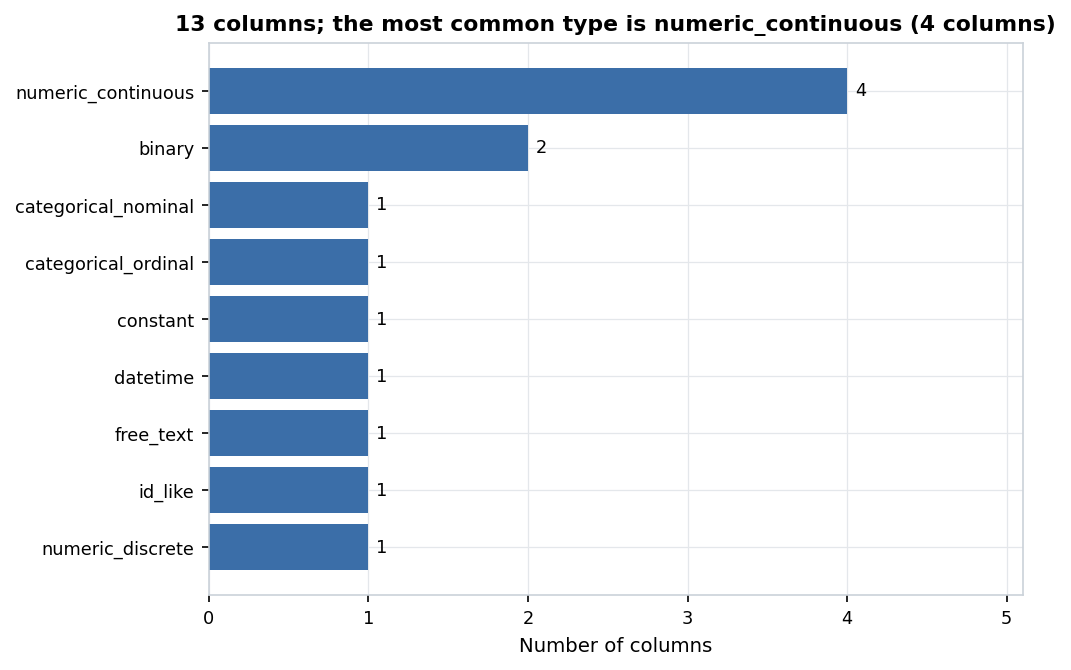

#### 7 of 13 columns have missing values; most is 'notes' (70.3%)
*Figure 2. 7 of 13 columns have missing values; most is 'notes' (70.3%).* Percent of rows missing per column (only columns with at least one gap). Red bars are above 40%.


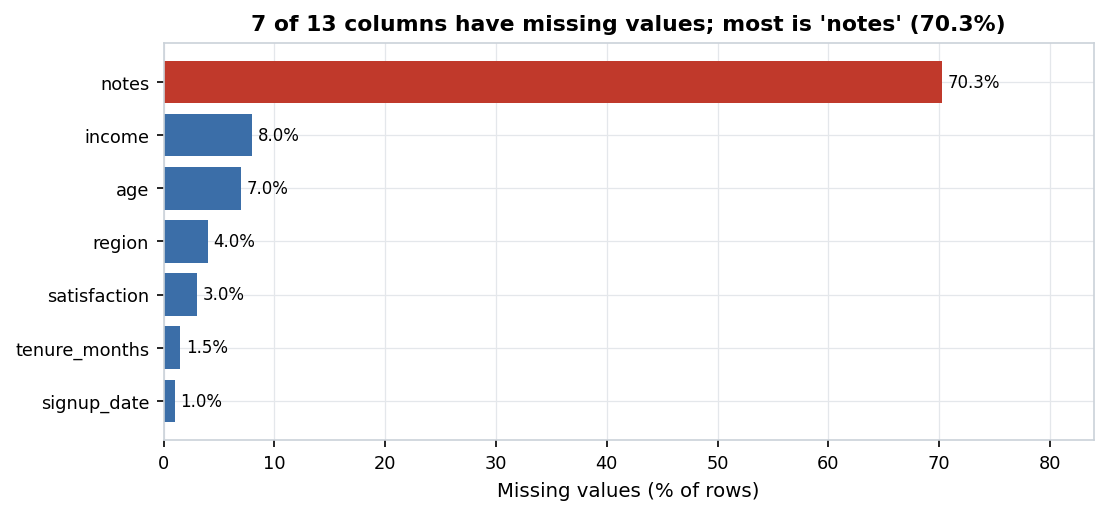

#### Missing values are spread out: the 10% of rows with the most gaps hold 22.84% of all missing cells
*Figure 3. Missing values are spread out: the 10% of rows with the most gaps hold 22.84% of all missing cells.* Each red cell is a missing value; rows are sorted by how many gaps they have. A random sample of 500 of 2,000 rows is shown.


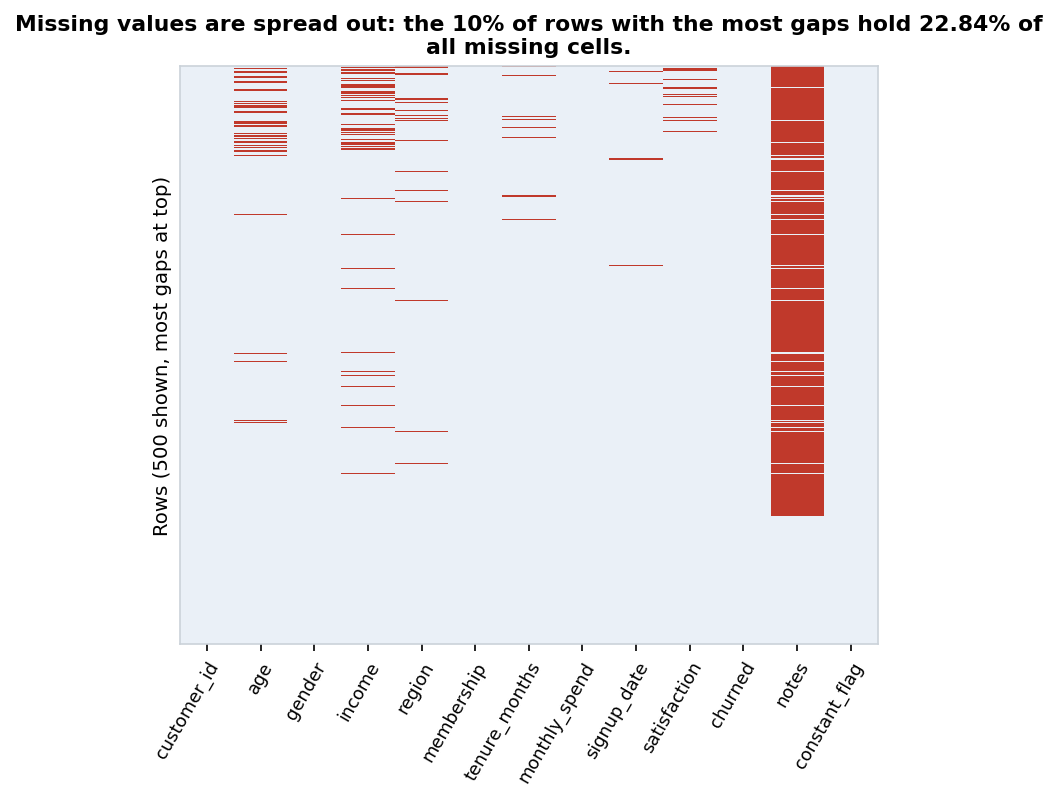

#### Missingness in 'income' and 'region' moves together most (r = +0.03)
*Figure 4. Missingness in 'income' and 'region' moves together most (r = +0.03).* Correlation between the missing/not-missing patterns of columns with gaps. High values mean the gaps tend to occur in the same rows. Descriptive only.


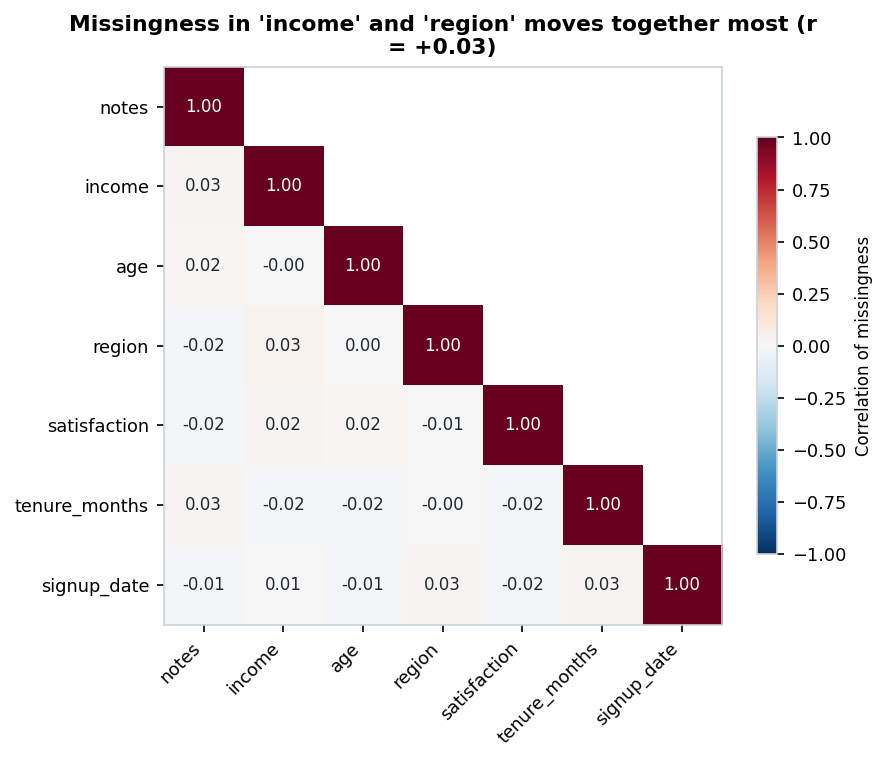

#### Numeric distributions (1/1): most skewed here is 'monthly_spend' (skew +17.99)
*Figure 5. Numeric distributions (1/1): most skewed here is 'monthly_spend' (skew +17.99).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


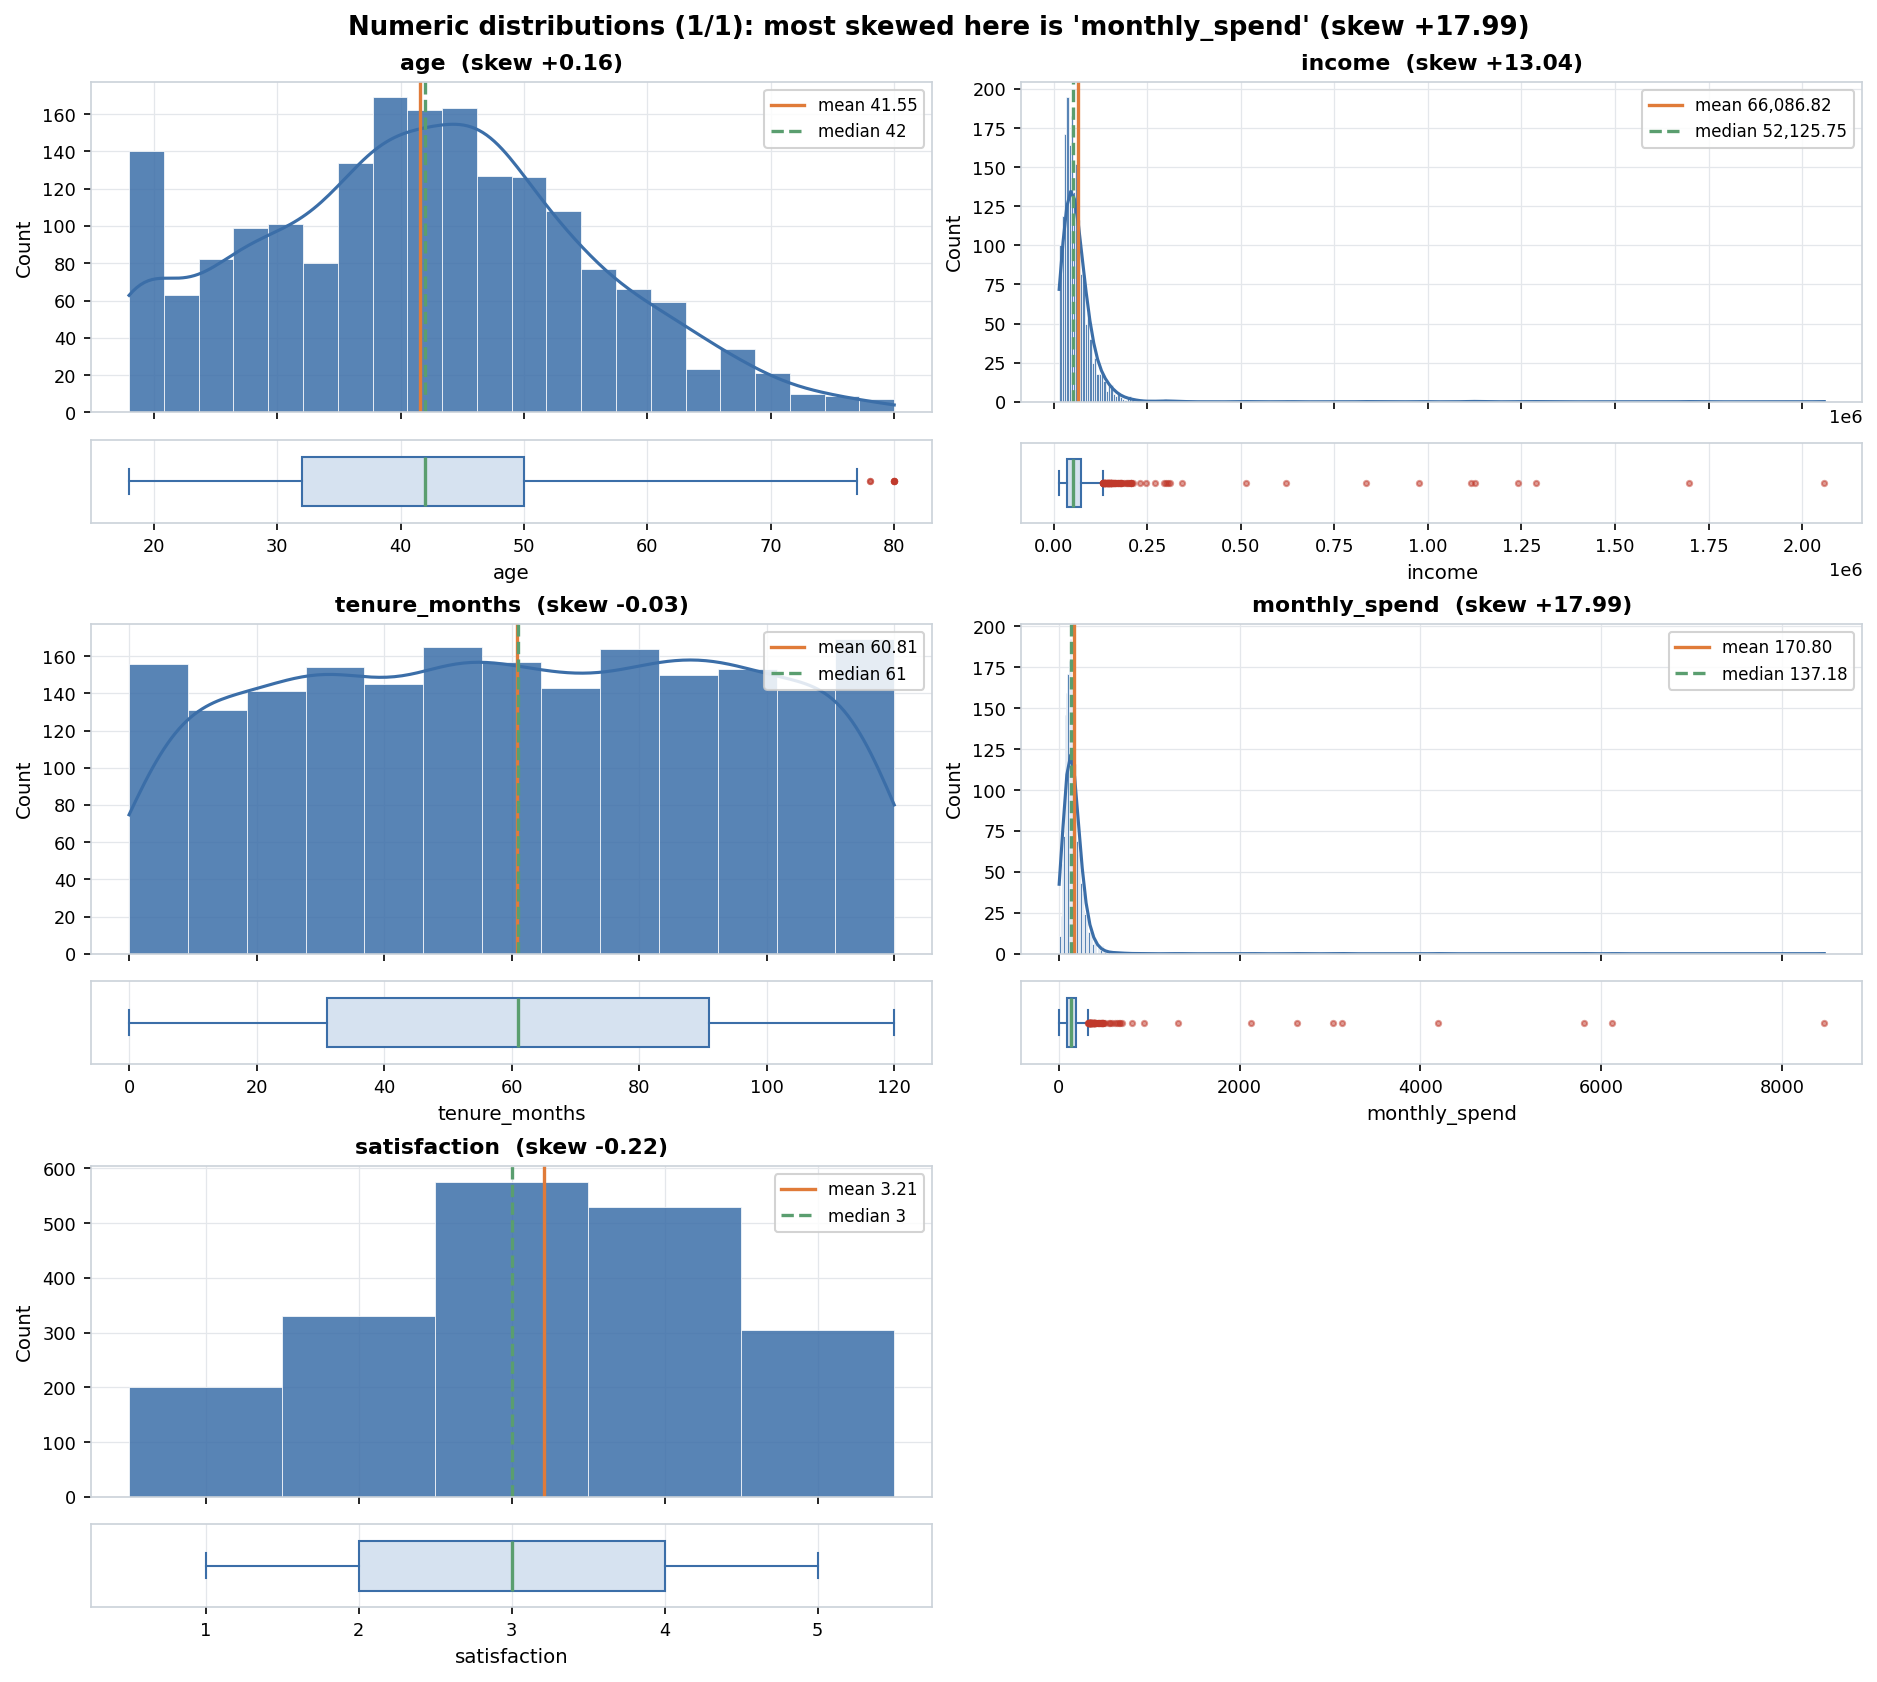

#### 'monthly_spend' is right-skewed (skew +17.99)
*Figure 6. 'monthly_spend' is right-skewed (skew +17.99).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


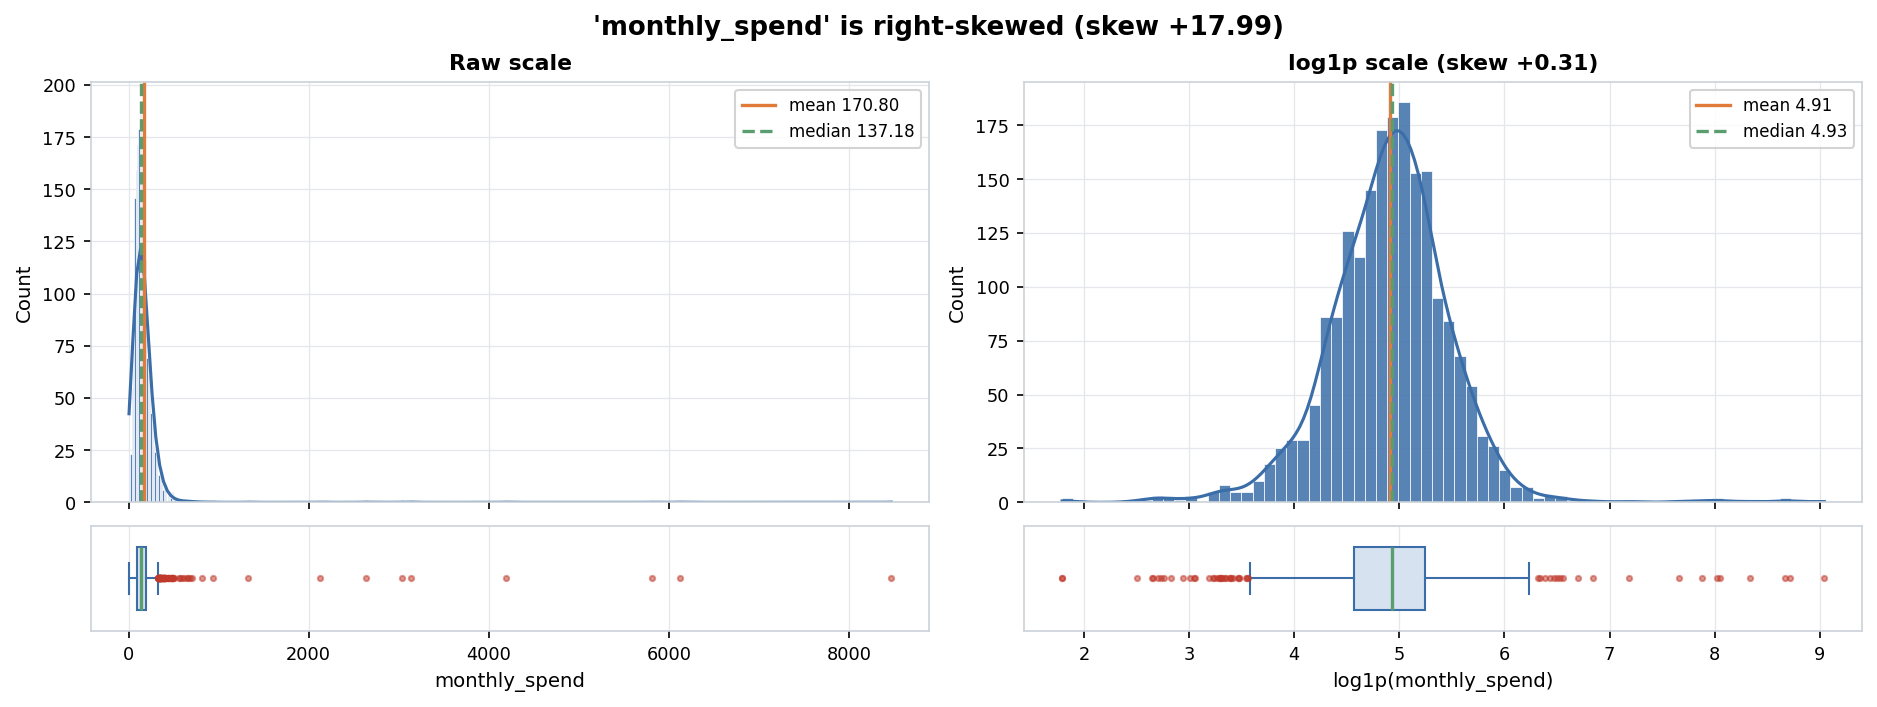

#### 'income' is right-skewed (skew +13.04) and has 5.3% IQR outliers
*Figure 7. 'income' is right-skewed (skew +13.04) and has 5.3% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


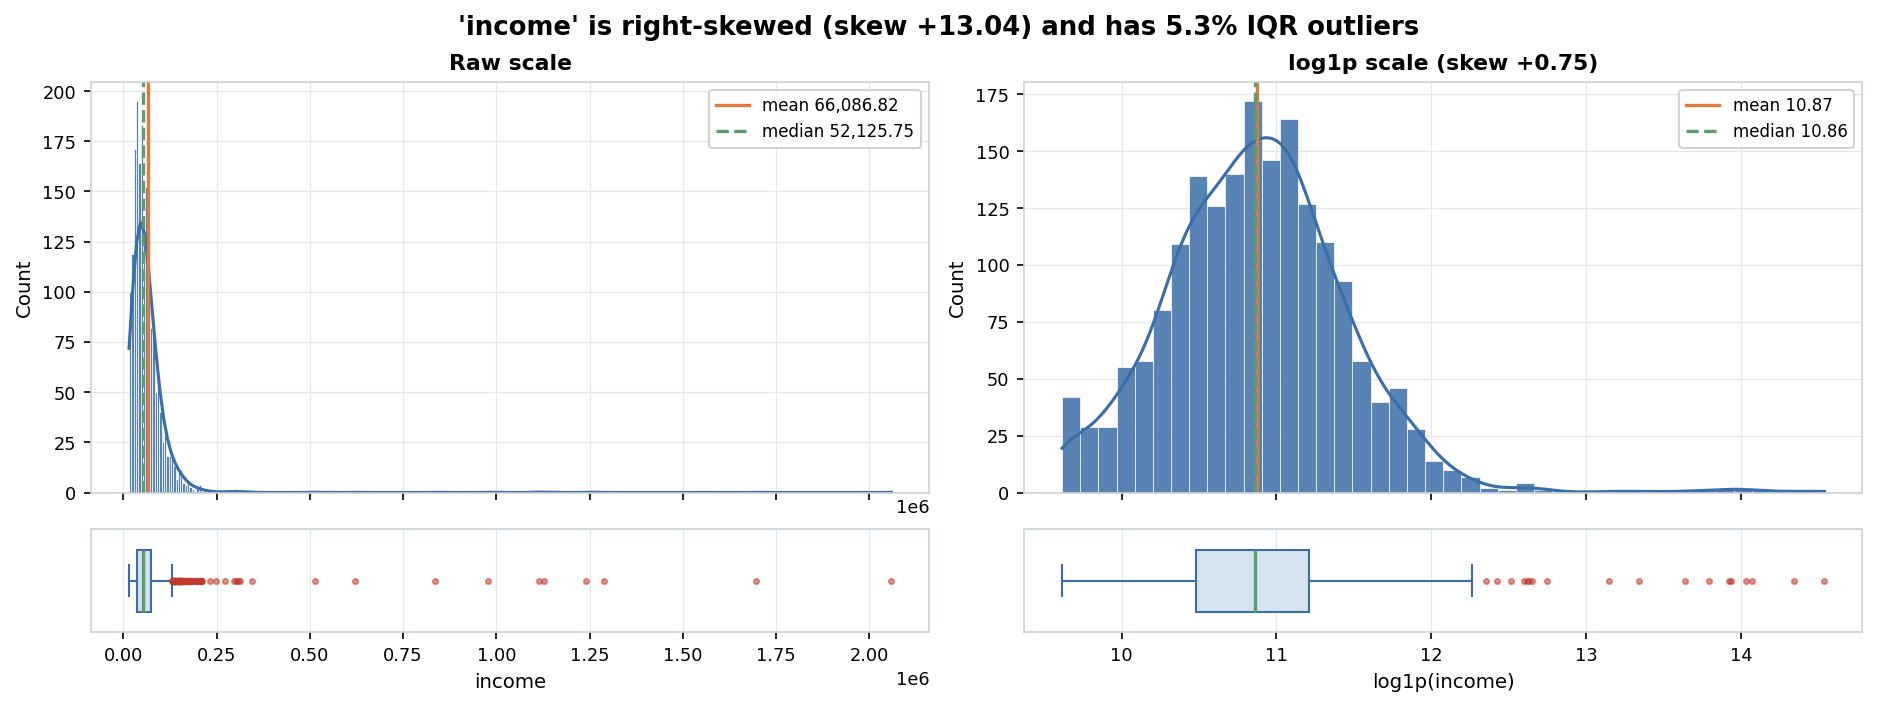

#### 'income' has the most IQR outliers (5.3% of its values)
*Figure 8. 'income' has the most IQR outliers (5.3% of its values).* Share of each numeric column's values outside 1.5×IQR. Outliers are only flagged, not removed, in the conservative cleaned data. Red bars are above the guide line.


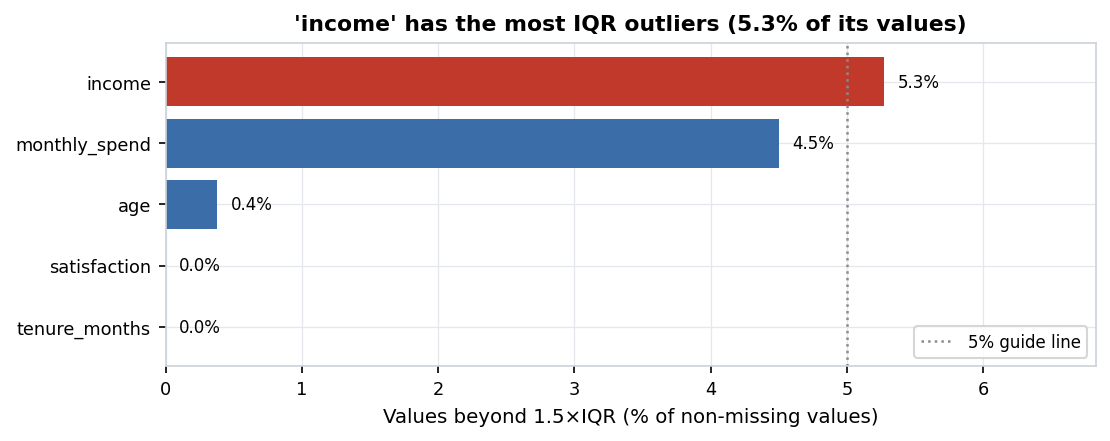

#### Categorical distributions (1/1): most lopsided here is 'churned' (top level 65.8%)
*Figure 9. Categorical distributions (1/1): most lopsided here is 'churned' (top level 65.8%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


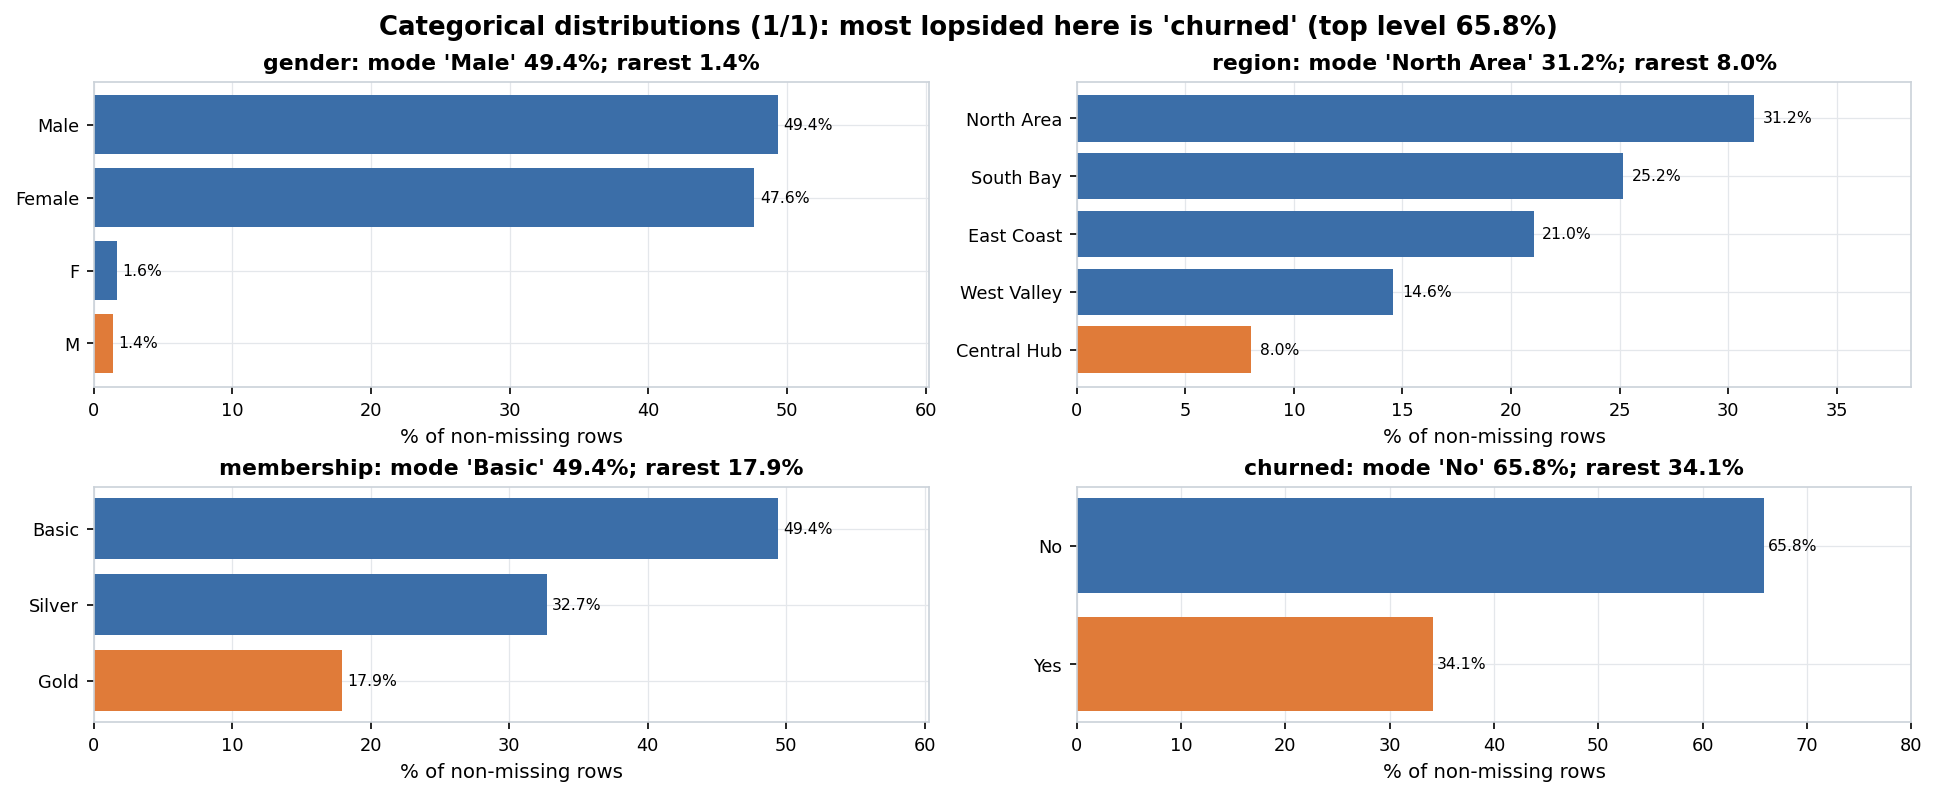

#### 'region' has the most levels (5)
*Figure 10. 'region' has the most levels (5).* Number of distinct values in each categorical or binary column.


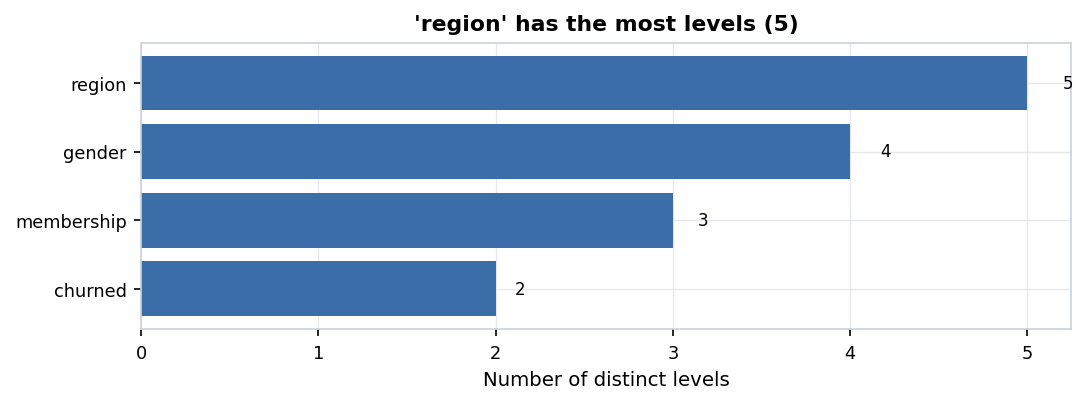

#### Target 'churned' is mildly imbalanced: smallest class 'Yes' is 34.1% of rows (ratio 1.93:1)
*Figure 11. Target 'churned' is mildly imbalanced: smallest class 'Yes' is 34.1% of rows (ratio 1.93:1).* Rows per target class. The orange bar is the smallest class. Highly imbalanced = smallest class under 10% of rows; mildly = largest/smallest ratio of 1.5 or more.


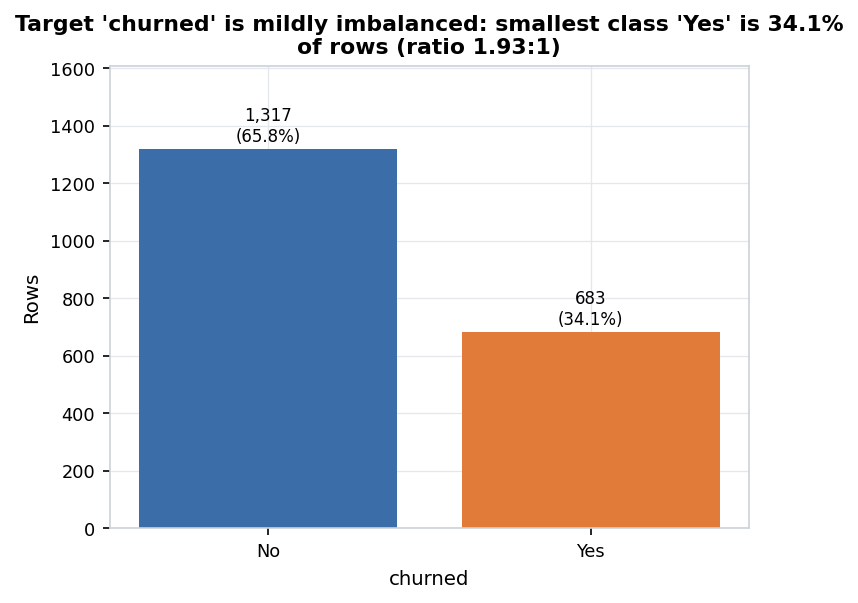

#### The 'churned' mix changes most across levels of 'membership' (Cramér's V 0.01)
*Figure 12. The 'churned' mix changes most across levels of 'membership' (Cramér's V 0.01).* Share of each target class within each level of the categorical features most associated with the target (bias-corrected Cramér's V). Descriptive coefficients only; no hypothesis tests were run.


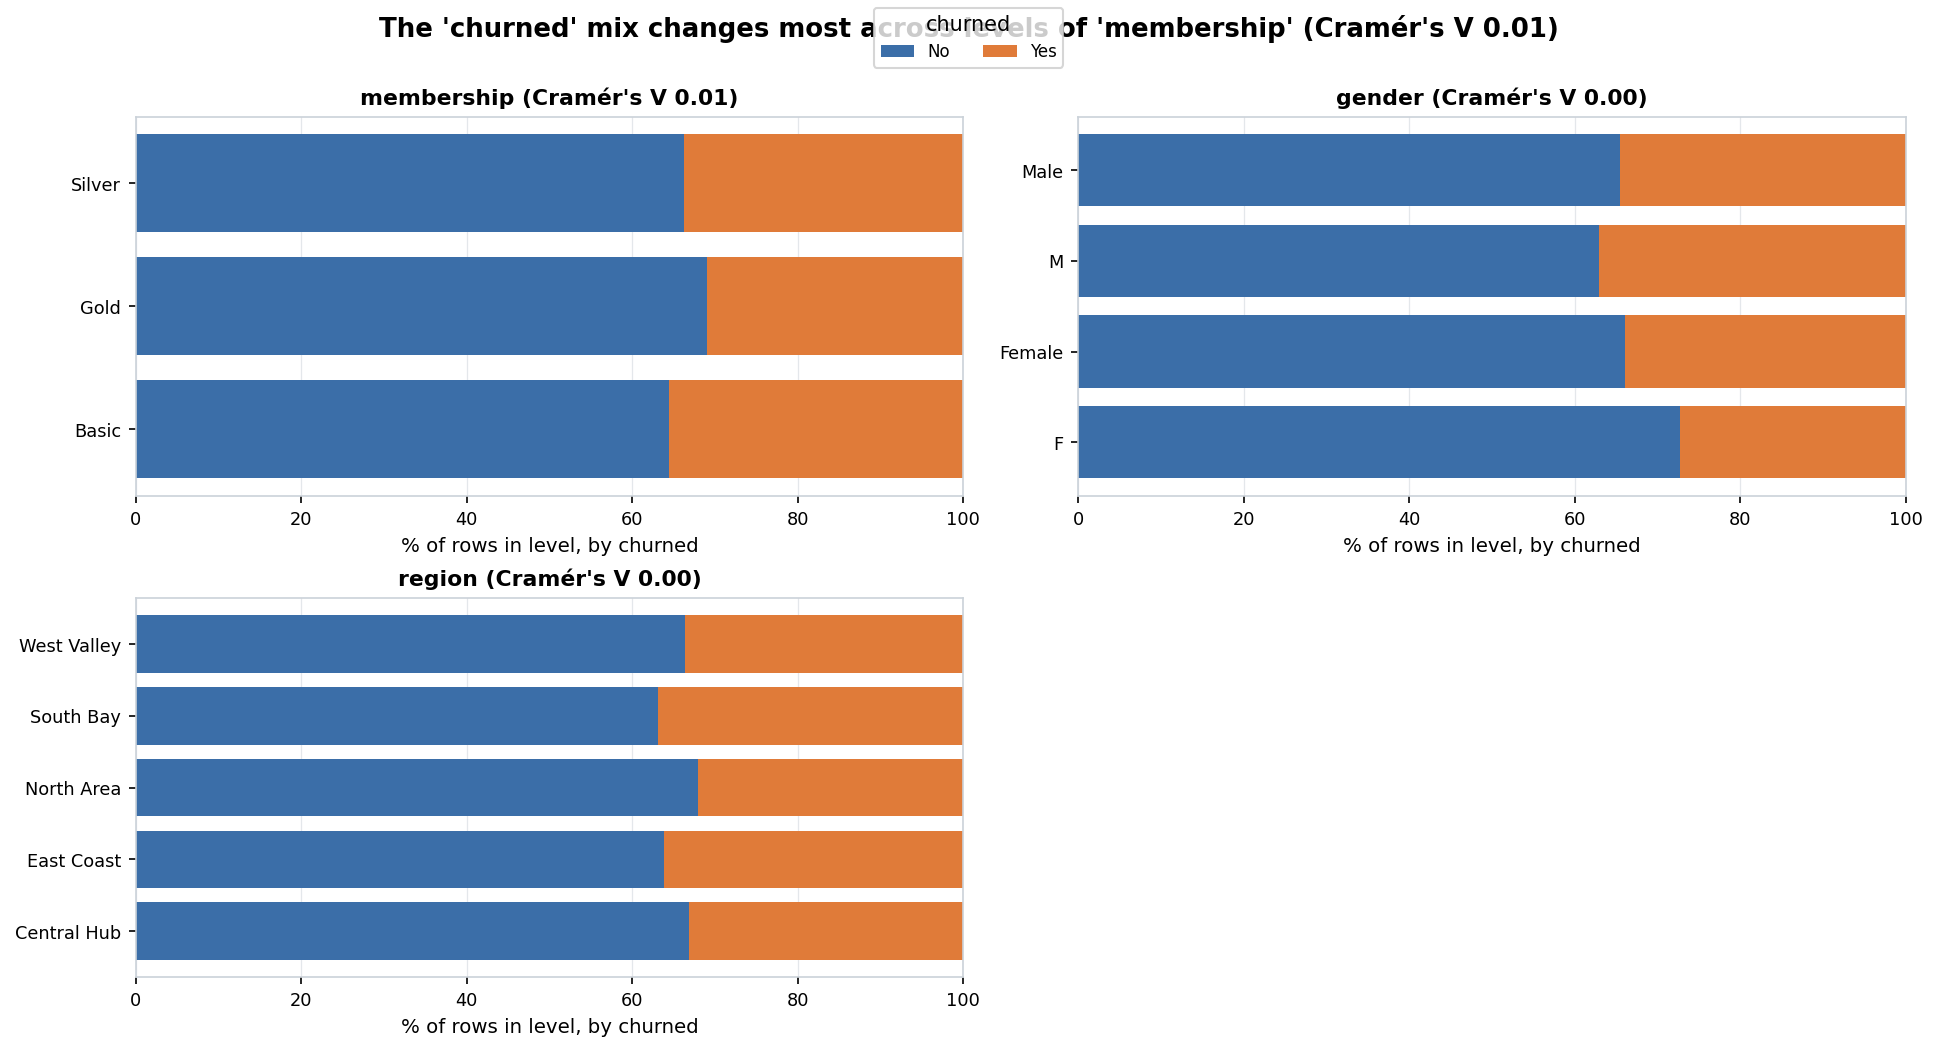

#### Strongest numeric pair: 'income' vs 'monthly_spend' (Spearman +0.89, Pearson +0.09)
*Figure 13. Strongest numeric pair: 'income' vs 'monthly_spend' (Spearman +0.89, Pearson +0.09).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


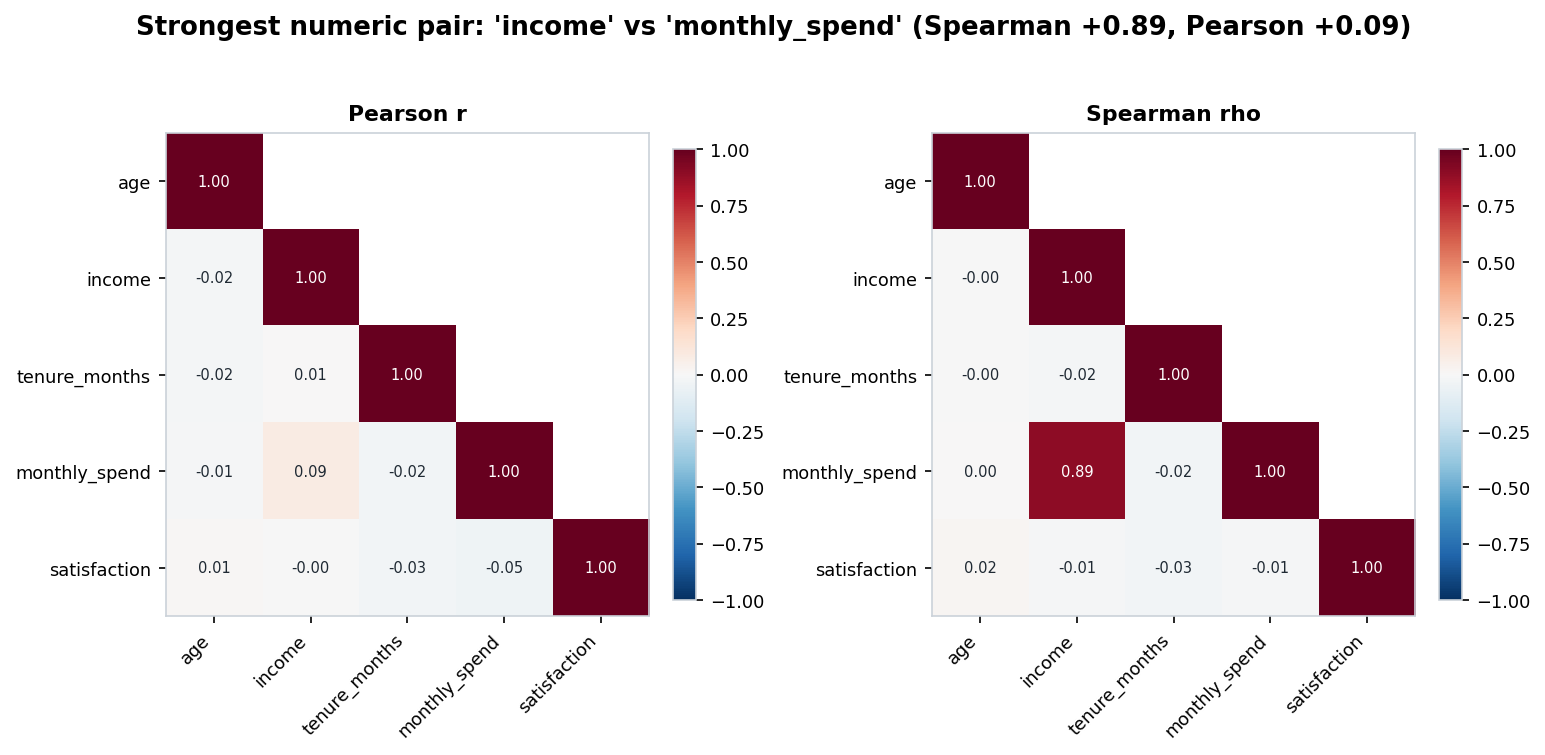

#### Top 6 numeric pairs by |Spearman rho|
*Figure 14. Top 6 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


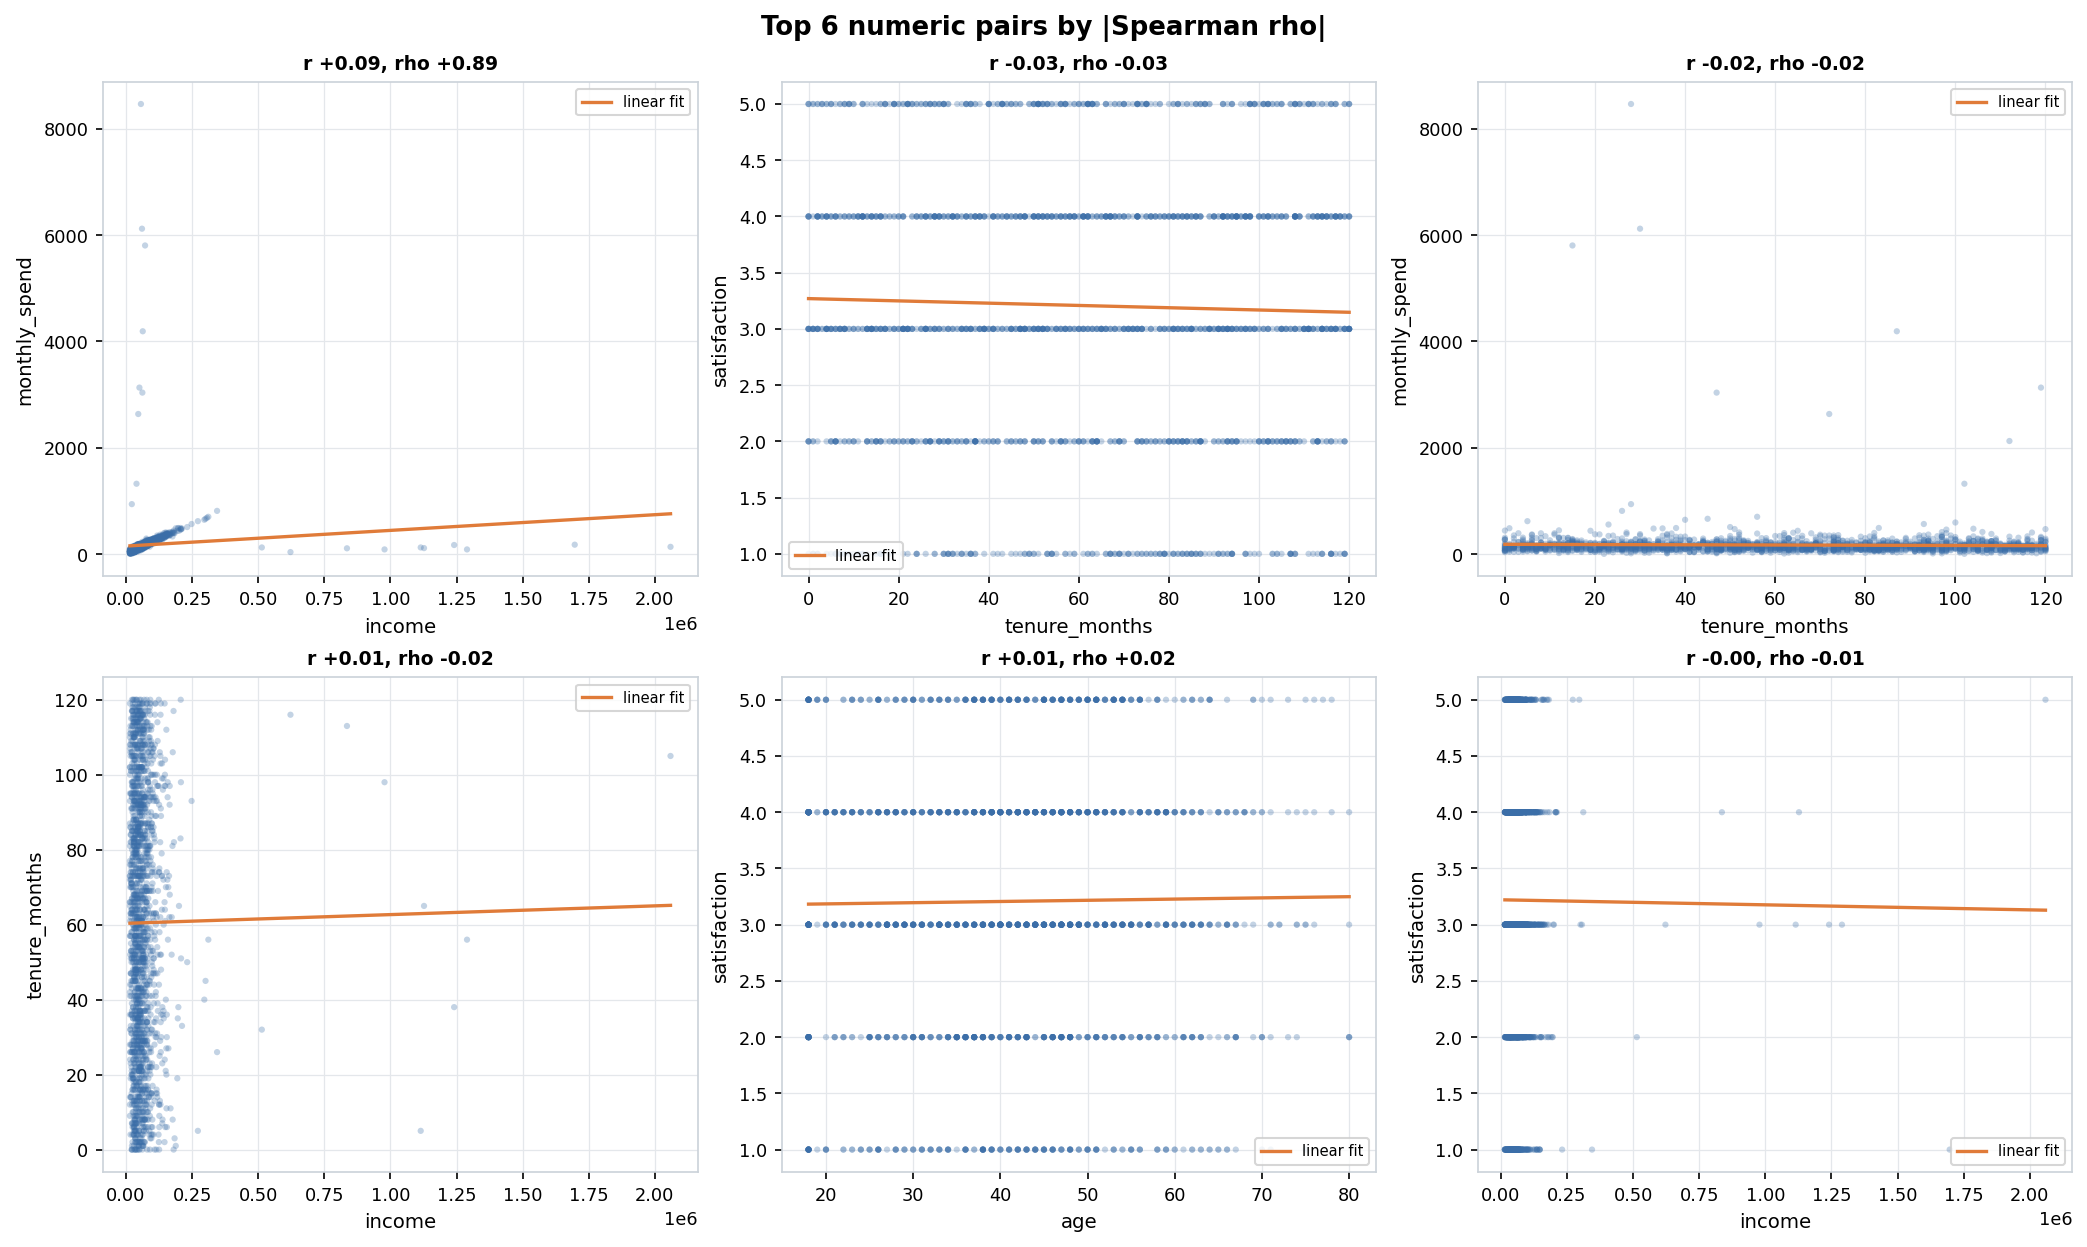

#### 'churned' separates 'tenure_months' the most (eta² 0.10 = share of its spread explained by the groups)
*Figure 15. 'churned' separates 'tenure_months' the most (eta² 0.10 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


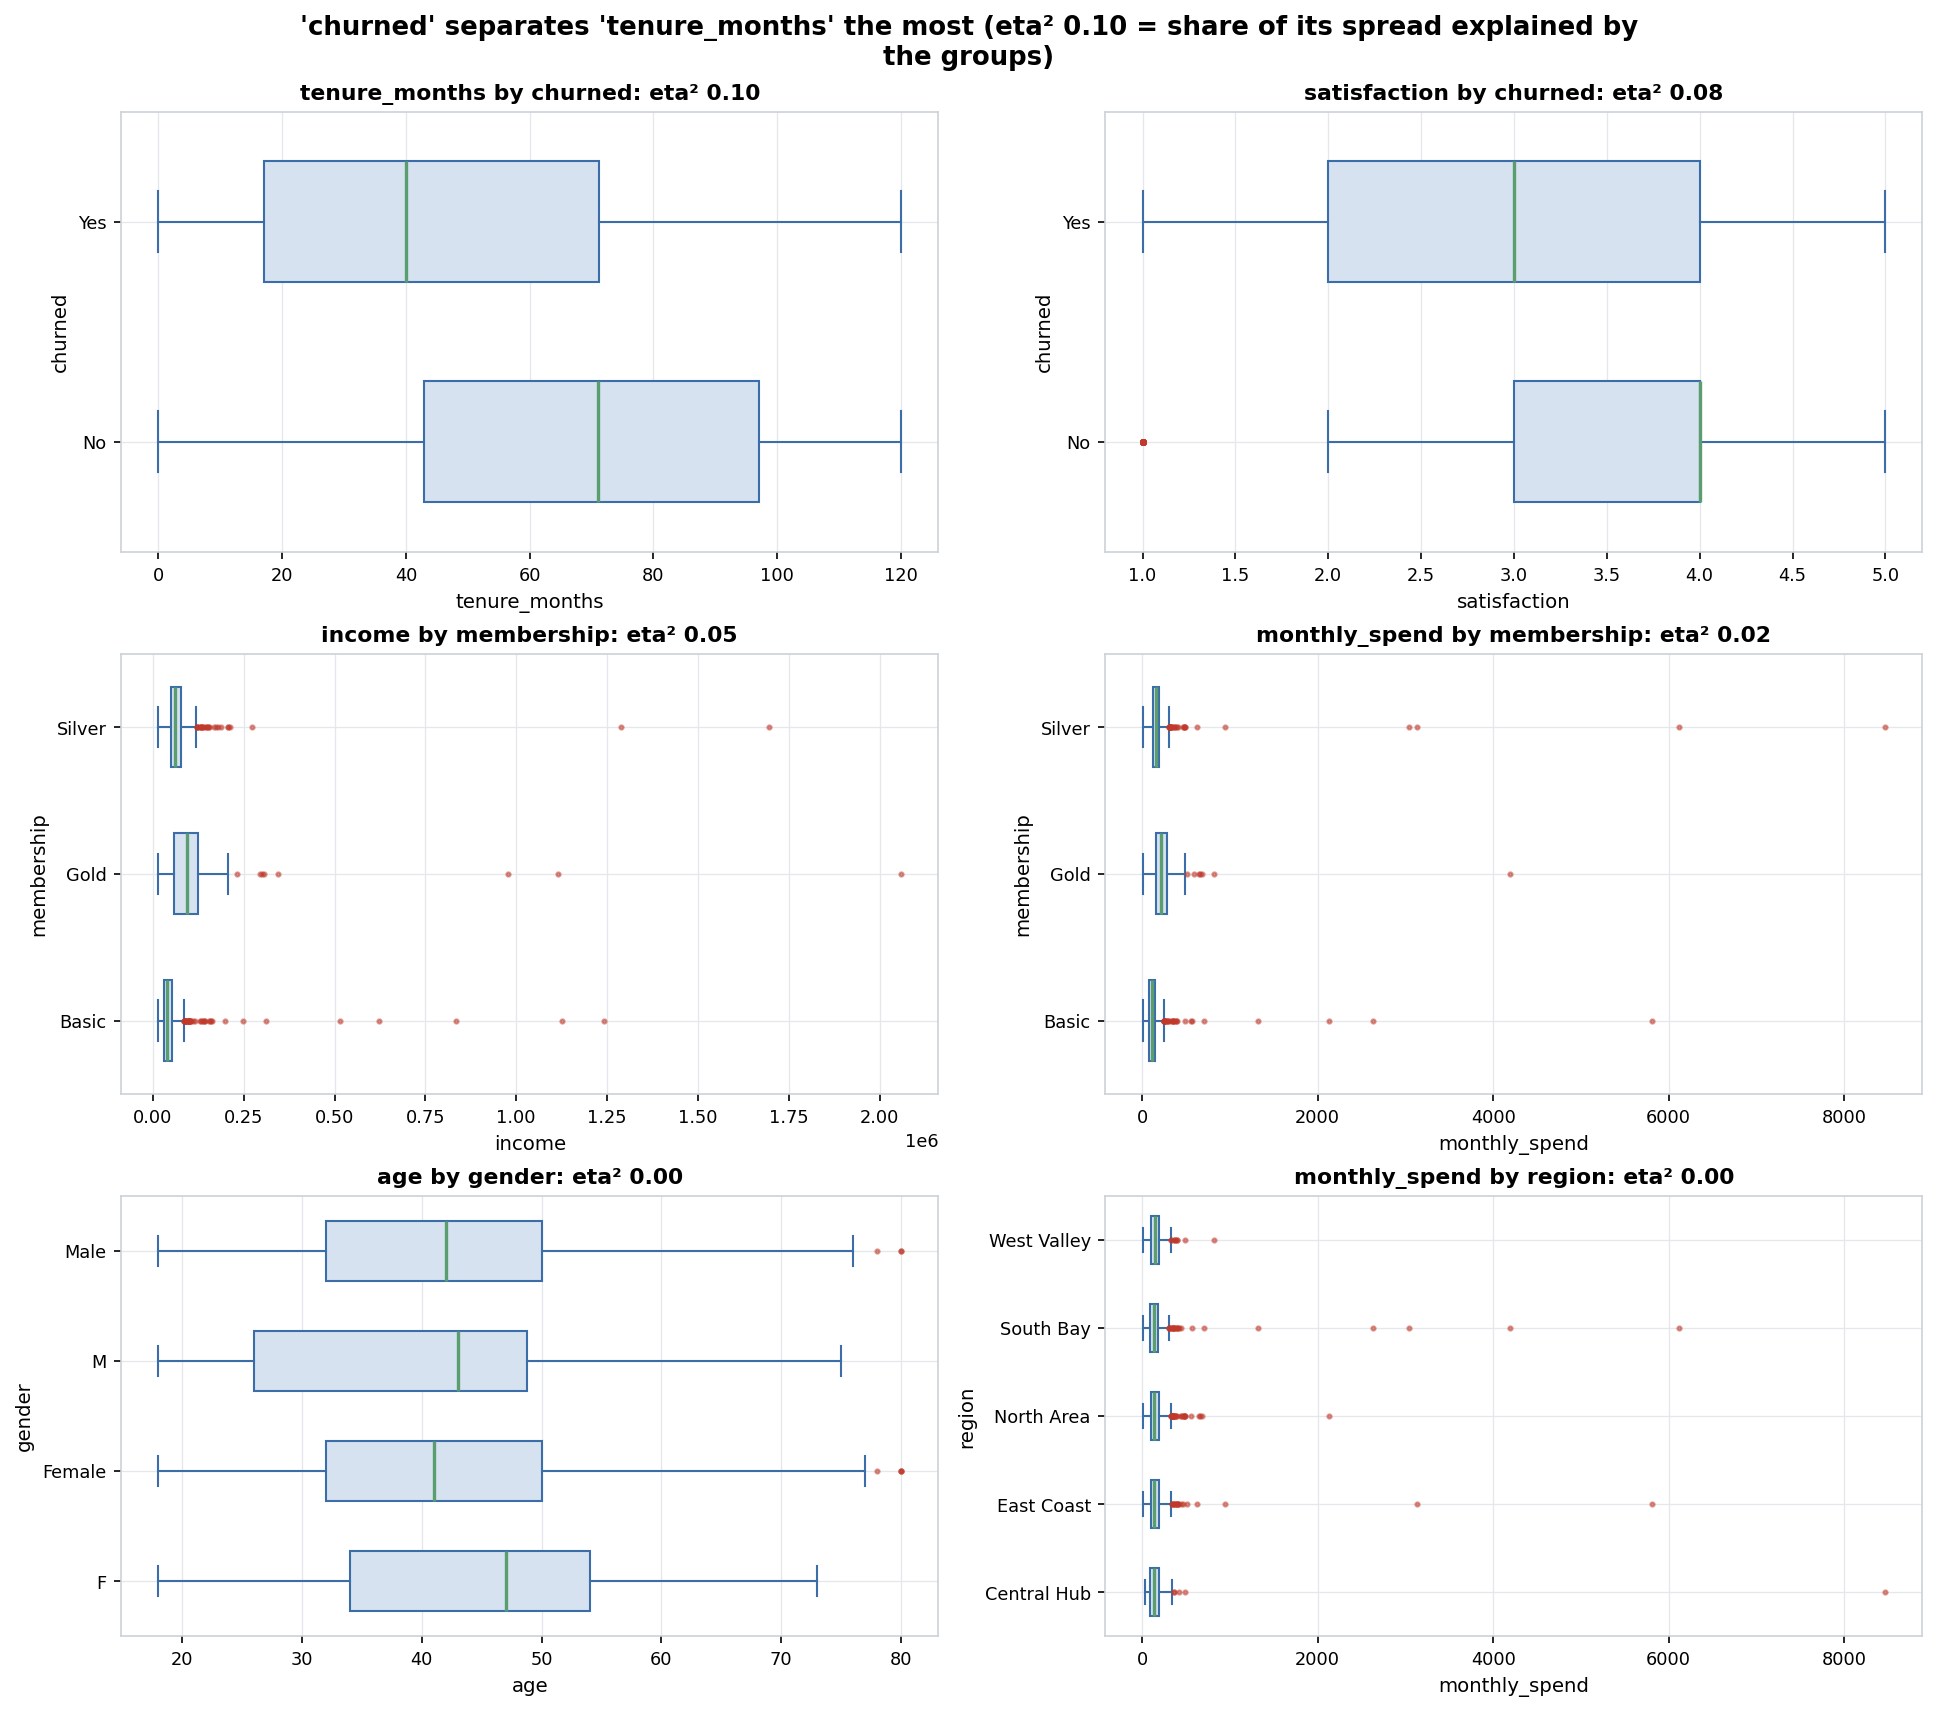

#### Strongest categorical pair: 'membership' vs 'churned' (Cramér's V 0.01)
*Figure 16. Strongest categorical pair: 'membership' vs 'churned' (Cramér's V 0.01).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


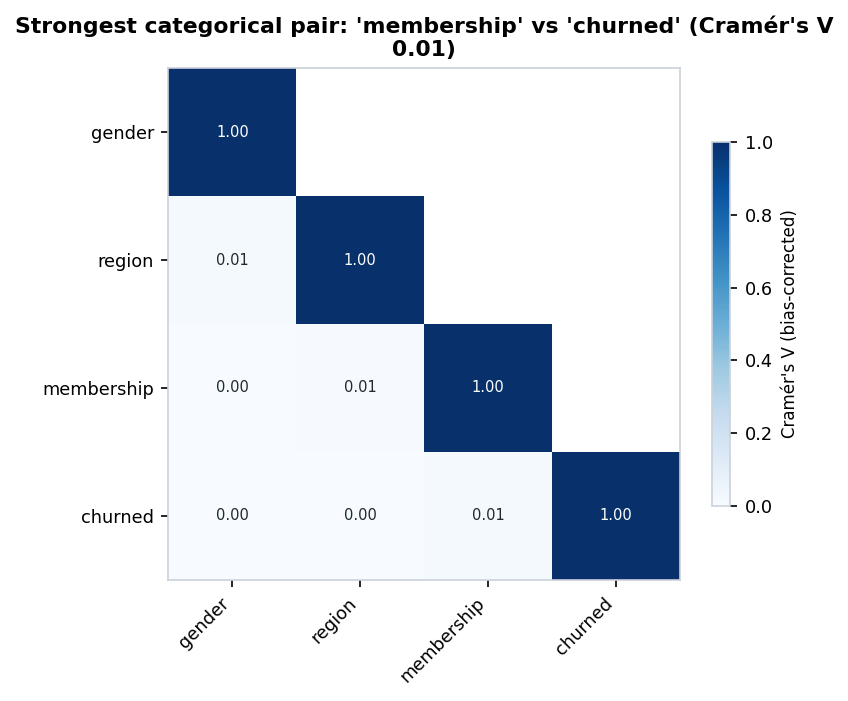

#### Level-by-level mix for the most associated categorical pairs
*Figure 17. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


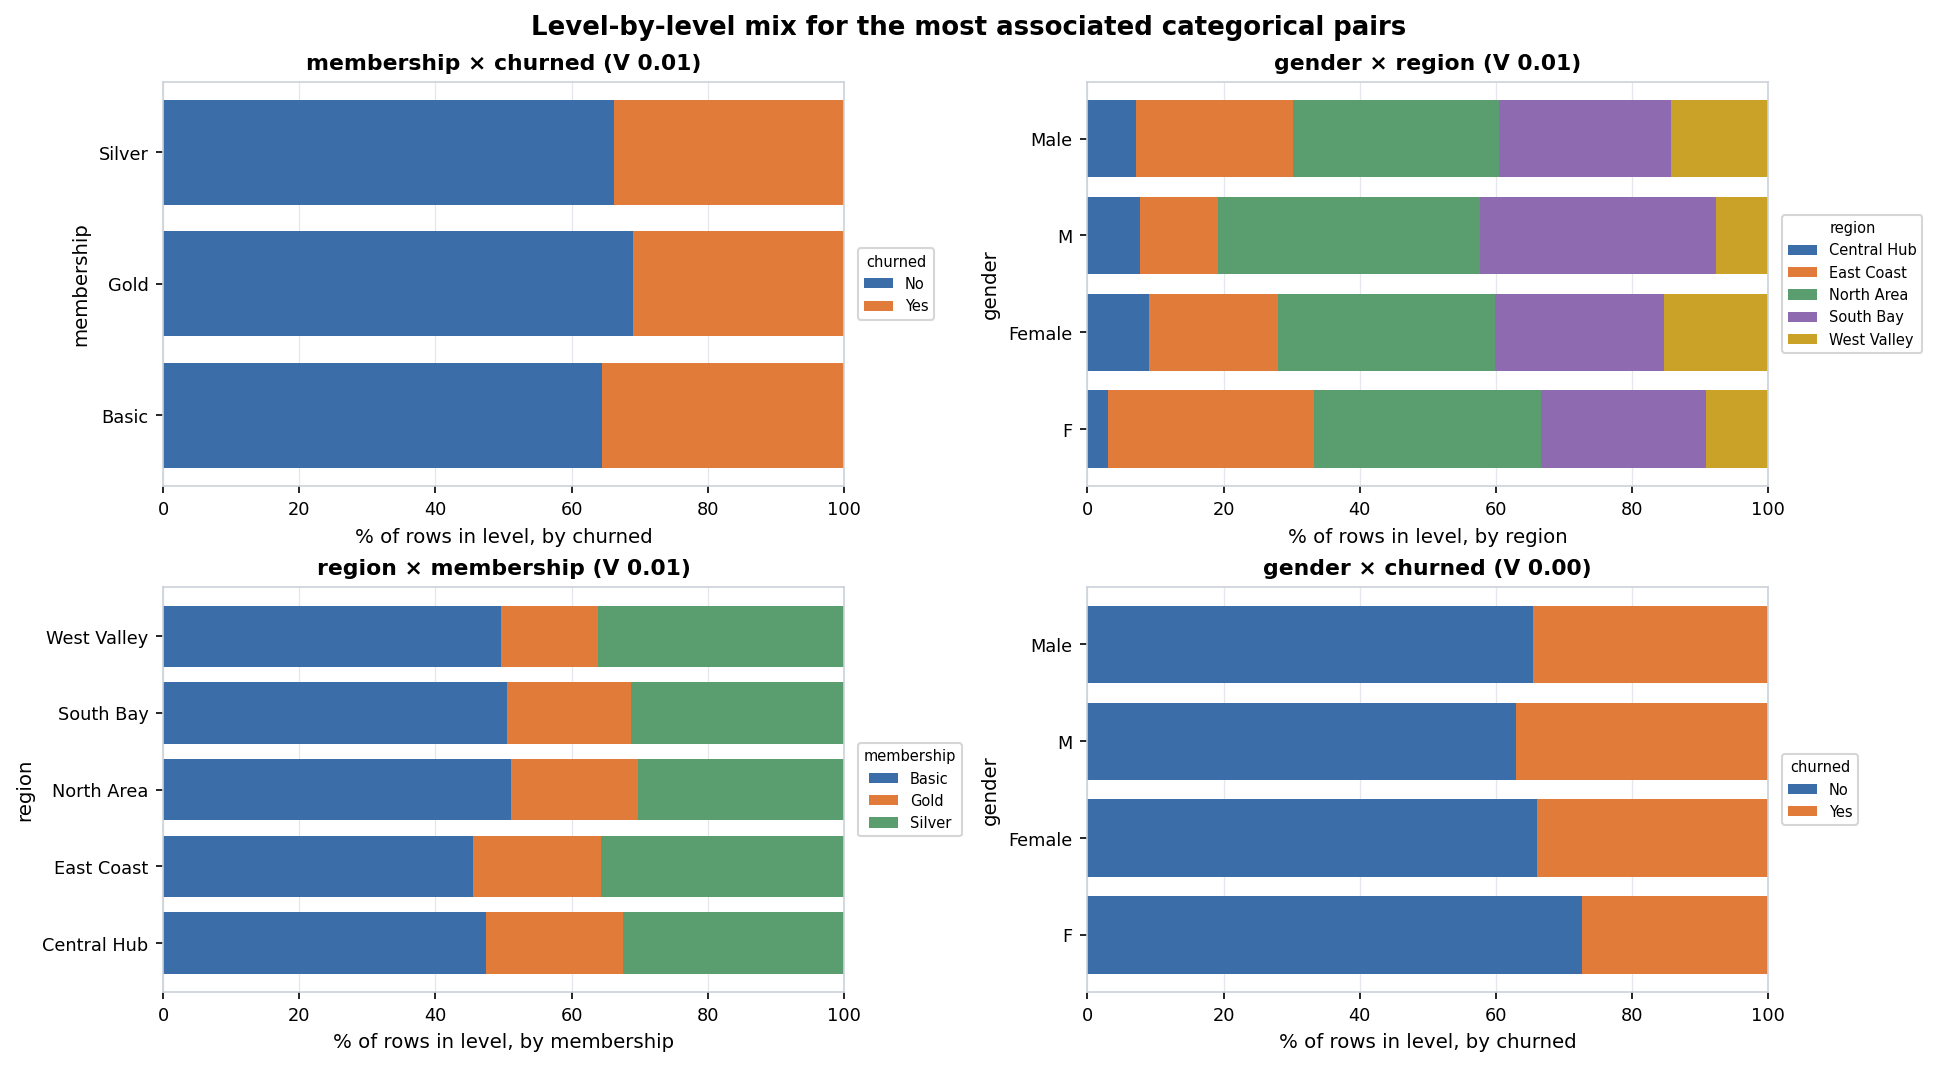

#### 'tenure_months' has the strongest association with 'churned' (eta² 0.10)
*Figure 18. 'tenure_months' has the strongest association with 'churned' (eta² 0.10).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


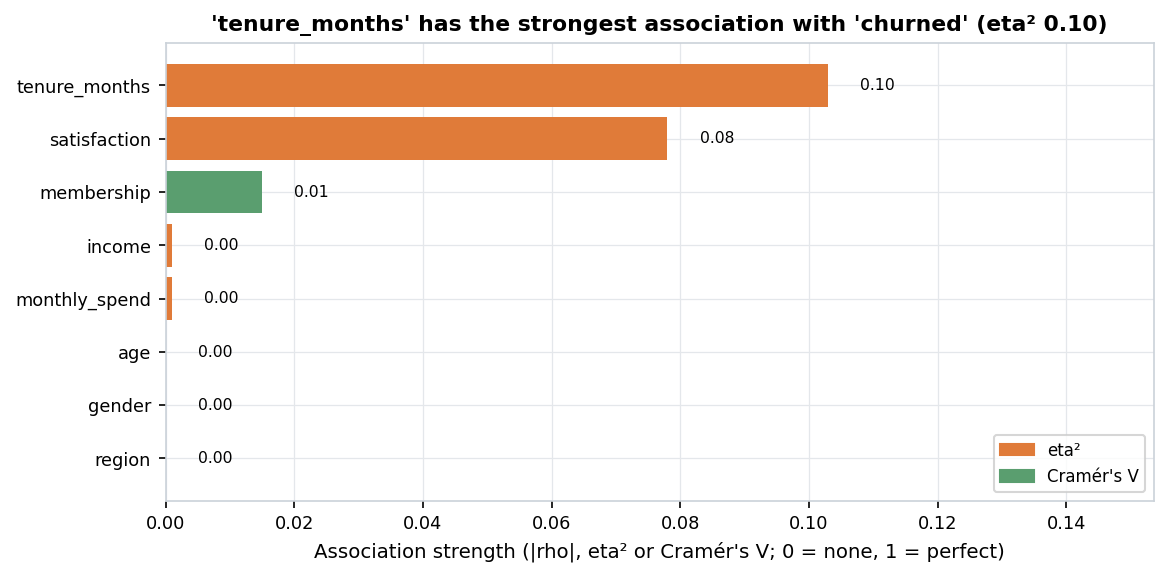

#### 'signup_date' runs from 2020-01-01 to 2024-12-29; largest gap between records is 8 days
*Figure 19. 'signup_date' runs from 2020-01-01 to 2024-12-29; largest gap between records is 8 days.* Number of rows per month for 'signup_date'.


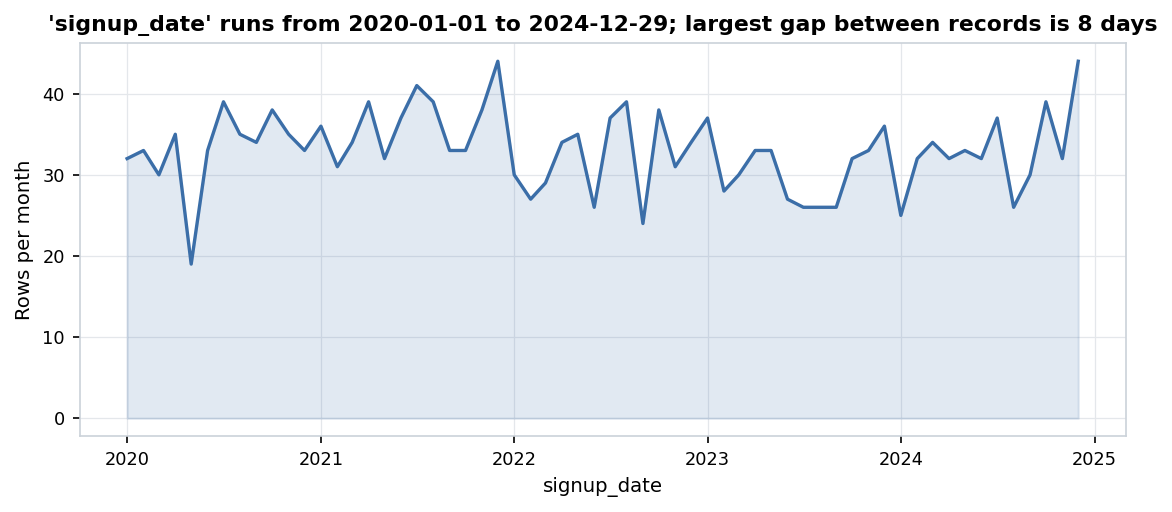

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `messy_synthetic`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [income, monthly_spend] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `93652.5419`
- **Min standard deviation:** `1.1998`
- **Scale disparity ratio (`max_std / min_std`):** `78059.53x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `age` | 0.158 | -0.420 | 18 | 80 | 13.385 | True | `none` | Moderate/low skewness (skew=0.16); no non-linear transform needed. |
| `income` | 13.040 | 214.622 | 15000 | 2.05922e+06 | 93652.542 | True | `log1p` | Right-skewed (skew=13.04 > 1.0) with non-negative domain (min=15000); log1p recommended. |
| `tenure_months` | -0.030 | -1.173 | 0 | 120 | 34.601 | True | `none` | Moderate/low skewness (skew=-0.03); no non-linear transform needed. |
| `monthly_spend` | 17.986 | 387.119 | 5 | 8468.39 | 313.020 | True | `log1p` | Right-skewed (skew=17.99 > 1.0) with non-negative domain (min=5); log1p recommended. |
| `satisfaction` | -0.221 | -0.806 | 1 | 5 | 1.200 | True | `none` | Moderate/low skewness (skew=-0.22); no non-linear transform needed. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\messy_synthetic_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `messy_synthetic`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **HIGH** — Column 'notes' has 70.3% missing values (n = 1,406 of 2,000 rows). ([figure](figures/missing_bar.png))
- **MEDIUM** — Column 'Unnamed: 0' was dropped (exported_unnamed_index_column).
- **MEDIUM** — Column 'unused' was dropped (fully_empty_column).
- **MEDIUM** — 80 exact duplicate rows were removed (the first copy of each was kept).
- **MEDIUM** — Column 'age' had 21 values outside its allowed range; they were set to missing.
- **MEDIUM** — Column 'tenure_months' had 11 values outside its allowed range; they were set to missing.
- **MEDIUM** — Column 'age' has 7% missing values (n = 140 of 2,000 rows). ([figure](figures/missing_bar.png))
- **MEDIUM** — Column 'income' has 8% missing values (n = 160 of 2,000 rows). ([figure](figures/missing_bar.png))
- **MEDIUM** — Column 'income' was stored as text with number formatting; 1,914 cells were converted to numbers.
- **MEDIUM** — Column 'monthly_spend' was stored as text with number formatting; 2,080 cells were converted to numbers.
- **MEDIUM** — Column 'income' used placeholder text for missing values: '-' (39), '?' (36), 'N/A' (26), 'null' (25); 126 cells were turned into real missing values.
- **MEDIUM** — Column 'signup_date' had 21 values that could not be read as its type; they were set to missing.
- **MEDIUM** — Column 'tenure_months' had 20 values that could not be read as its type; they were set to missing.
- **LOW** — Column 'churned' had labels that differed only by capitals or spaces; 47 cells were merged into one spelling.
- **LOW** — Column 'gender' had labels that differed only by capitals or spaces; 226 cells were merged into one spelling.
- **LOW** — Column 'membership' had labels that differed only by capitals or spaces; 20 cells were merged into one spelling.
- **LOW** — Column 'region' has 4% missing values (n = 80 of 2,000 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'satisfaction' has 3% missing values (n = 60 of 2,000 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'signup_date' has 1% missing values (n = 20 of 2,000 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'tenure_months' has 1.5% missing values (n = 30 of 2,000 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'region' used placeholder text for missing values: 'Unknown' (83); 83 cells were turned into real missing values.
- **INFO** — Column 'constant_flag' is constant and is left out of the analysis (kept in the cleaned file).
- **INFO** — Column 'customer_id' is ID-like and is left out of the analysis (kept in the cleaned file).
- **INFO** — Column 'notes' is free text and is left out of the analysis (kept in the cleaned file).

### Distributions

- **MEDIUM** — 'income' has many outliers: 5.27% of its values (n = 97) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'income' is right-skewed (skew = 13.04): its median (52,125.75) is below its mean (66,086.82), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_income.png))
- **MEDIUM** — 'monthly_spend' is right-skewed (skew = 17.99): its median (137.18) is below its mean (170.8), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_monthly_spend.png))
- **LOW** — 'age' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))

### Class balance

- **MEDIUM** — Target 'churned' is mildly imbalanced: the smallest class 'Yes' is 34.15% of rows and the largest 'No' is 65.85% (the largest class is 1.93 times the smallest). ([figure](figures/target_balance.png))

### Relationships (descriptive)

- **LOW** — 'income' and 'monthly_spend' rise together (Spearman rho = +0.89, Pearson r = +0.09; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — The categorical feature most associated with target 'churned' is 'membership' (Cramér's V = 0.01; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — The numeric feature most associated with target 'churned' is 'tenure_months' (eta² = 0.1; descriptive). ([figure](figures/target_relationships.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 78,059.53 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.
- **INFO** — Scaling note: log1p is recommended for 'income' (skew = 13.04) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'monthly_spend' (skew = 17.99) for plots and parametric models only; the main cleaned file is not transformed.

### Implications for later testing

- **MEDIUM** — Rank-based methods (Spearman, Mann-Whitney, Kruskal-Wallis) are recommended for 2 skewed or outlier-heavy column(s): 'income', 'monthly_spend'.
- **MEDIUM** — Because target 'churned' is mildly imbalanced, compare groups using rates (% per class) rather than raw counts, and use stratified splits for any later modeling. ([figure](figures/target_balance.png))

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Contamination-free ground-truth benchmark:** Generated from a 2,000-row seeded base dataset (`seed = 42`) with 18 injected defect categories recorded in `data/synthetic/messy_manifest.json` so pipeline cleaning and LLM baselines can be scored against an exact answer key.
- **Structural defect recovery (`17 -> 15` columns, `2,040 -> 2,000` rows):** The pipeline automatically dropped `Unnamed: 0` (exported index) and `all_null_col` (100% missing), flagged `constant_col` (`role = excluded`), and removed all 40 injected exact & whitespace-padded duplicate rows.
- **Type & formatting recovery with zero cell damage:** Successfully stripped currency/comma/accounting formatting in `monthly_spend` (`$1,234.50`, `(45.00)`), parsed percentage strings in `discount_rate` (`15%`), unified mixed ISO/slash/text dates in `signup_date`, merged 200 case/whitespace variants in `region`, and flagged 32 near-duplicate fuzzy typos (`"Nroth"`) without corrupting any clean cells.
- **Domain validity enforcement:** Detected and converted 39 impossible domain values to `NaN` (`age < 0` or `age > 120`, negative `tenure_months`, and `satisfaction_score = 99` outside `[1, 5]`).
- **Planted ground-truth relationships preserved:** After cleaning, the planted statistical structure remains intact: `tenure_months` and `monthly_spend` drive `total_spend` (Spearman $\rho = +0.76$), `plan_tier` strongly stratifies `monthly_spend` ($\eta^2 = 0.61$), and `churned` is associated with lower `satisfaction_score`, shorter `tenure_months`, and higher `support_tickets`.
- **Target findings for Phase 5 benchmark recovery:** (1) `plan_tier <-> monthly_spend` ($\eta^2 = 0.61$), (2) `tenure_months / monthly_spend <-> total_spend` ($
ho = +0.76$), (3) `satisfaction_score <-> churned`, (4) `tenure_months <-> churned`, and (5) `support_tickets <-> churned`.
<!-- MANUAL:END -->
